# Neural operator for Saint-Venant equations

In [1]:
import matplotlib.pyplot as plt
import torch
from matplotlib.axes import Axes

import utilities as util
from operators import MultiExpertNeuralOperator
from utilities import set_plot_style

In [2]:
MODEL_PARAMS_PATH = "input/multi_branch_model_params.pt"
UDS_DATA_PATH = "input/sewer_network_dataset.npz"

## Load the learned neural operator for SVE

In [3]:
# * initialize the surrogate model
surrogate = MultiExpertNeuralOperator()
surrogate.load_models(MODEL_PARAMS_PATH)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
surrogate.to_device()

## Read the UDS data for model validation

In [4]:
db = util.Database(UDS_DATA_PATH)
data_dict  = {}
for diameter, model in surrogate.model_dict.items():
    count, features, labels = db.extract_dataset_for_diameter(diameter, device)
    data_dict[diameter] = (count, features, labels)

## Results

Speedup

In [5]:
T_CFD = 7720.9020  # seconds
dt_pred = util.predict_with_timing(surrogate, data_dict)
speedup = int(T_CFD / dt_pred)
util.print_device_specs(device)
print(f"CFD time:       {T_CFD:8.2f} s")
print(f"Surrogate time: {dt_pred:8.2f} s")
print(f"Speedup:        {speedup:8,d}x")

Using cuda device
CPU: Intel(R) Core(TM) Ultra 9 275HX
GPU: NVIDIA GeForce RTX 5070 Laptop GPU (7.9 GiB VRAM)
CFD time:        7720.90 s
Surrogate time:     0.41 s
Speedup:          19,001x


Accuracy

In [6]:
Y_pred_dict, Y_true_dict = util.predict_all_network(surrogate, data_dict)
Y_pred_all_arr = util.concat_dict(Y_pred_dict)
Y_true_all_arr = util.concat_dict(Y_true_dict)
y_pred_arr, q_pred_arr, y_true_arr, q_true_arr = util.parse_prediction(Y_pred_all_arr, Y_true_all_arr)
df_metric = util.get_metrics_table(Y_true_all_arr, Y_pred_all_arr, data_dict)
df_metric

,R2,NMAE
y,0.999265,0.3247%
q,0.999653,0.1809%


Visualize selected pipes

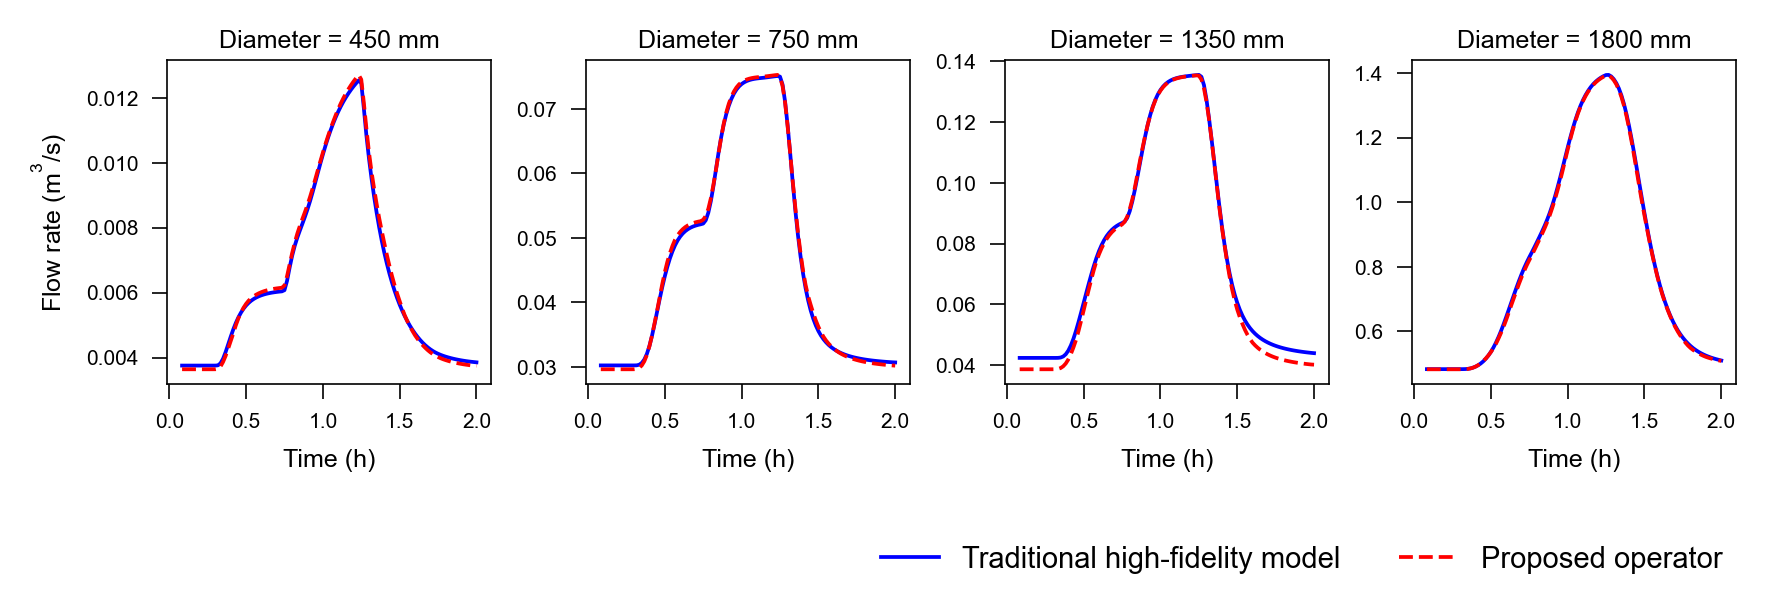

In [7]:
selected_pipe_indices = [
    "SWD4031468",
    "SWD4031540",
    "SWD4031301",
    "SBP4012900",
]
pipe_domain = {}
for pipe_id in selected_pipe_indices:
    # Prepare features
    variables = db.pipe_data[pipe_id]
    diameter = variables["d"]
    x_arr, t_arr, feature_arr, Y_true_arr = db.extract_pipe_dataset(pipe_id)
    features, labels = util.numpy_to_tensor(feature_arr, Y_true_arr, device)
    # Model inference
    Y_pred = surrogate.predict_batch(diameter, features)
    # Parse results
    Y_pred_arr = Y_pred.cpu().numpy()
    Y_true_arr = labels.cpu().numpy()
    Y_pred_domain_arr, Y_true_domain_arr = util.get_domain(len(x_arr), Y_pred_arr, Y_true_arr)
    pipe_domain[pipe_id] = (Y_pred_domain_arr, Y_true_domain_arr)
    
set_plot_style()
# Settings of the plot
line_color1 = "b"
line_color2 = "r"
lw = 0.9
alpha = 1.0
line_params_sve = dict(
    linestyle="-",
    linewidth=lw,
    label="SVE",
    color=line_color1,
    alpha=alpha,
)
line_params_pred = dict(
    linestyle="--",
    linewidth=lw,
    label="Predicted",
    color=line_color2,
    alpha=alpha,
)
# Initialize figure and axes
fig, axes = plt.subplots(1, 4, constrained_layout=True)
fig.set_size_inches(5.77, 2.2)
for ax in axes:
    ax: Axes
    ax.set_box_aspect(1)
    ax.set_xlabel("Time (h)")
axes[0].set_ylabel(r"Flow rate ($\mathrm{m^{3}/s}$)")
# plot the results
t_arr = db.t_arr[5:] / 60 / 60  # the model need at least 5 minutes of input
for i, pipe_id in enumerate(selected_pipe_indices):
    ax = axes[i]
    Y_true_domain_arr = pipe_domain[pipe_id][1]
    Y_pred_domain_arr = pipe_domain[pipe_id][0]
    d = db.pipe_data[pipe_id]["d"]
    (line1,) = ax.plot(t_arr, Y_true_domain_arr[:, -1, 1], **line_params_sve)
    (line2,) = ax.plot(t_arr, Y_pred_domain_arr[:, -1, 1], **line_params_pred)
    ax.set_title(f"Diameter = {d} mm", pad=3)
# Add figure legend
fig.legend(
    [line1, line2],
    ["Traditional high-fidelity model", "Proposed operator"],
    loc="upper right",
    frameon=False,
    bbox_to_anchor=(1.0, 0.05),
    fontsize=7,
    ncol=2,
)